# Archived intermediate PPO/LSTM experiment

Historical 20-day-window version. Despite the original filename `DRL_PPO+LSTM_without_seeds.ipynb`, its code contains a seed list and model initialization loop; training occurs outside that loop. Its saved results are not the final report experiment. Start with [the main notebook](../01_recurrent_ppo_lstm.ipynb).

The experiment code and saved plots are retained with setup and path cleanup only. This archive was not executed or validated as a runnable entry point. Generated models would go under `models/runs/intermediate/`.


In [ ]:
import torch
print("CUDA Available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Using device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))

CUDA Available: True
Device: Tesla T4
Using device: cuda


In [ ]:
# === SETUP BLOCK ===
# Install required libraries only if missing

# PPO + LSTM Portfolio Optimization Code with TensorBoard

import numpy as np
import pandas as pd
import yfinance as yf
from sklearn.preprocessing import StandardScaler
from collections import deque
import gymnasium as gym
from gymnasium import spaces
from sb3_contrib import RecurrentPPO
from stable_baselines3.common.vec_env import DummyVecEnv
from torch.utils.tensorboard import SummaryWriter
import matplotlib.pyplot as plt
import copy
import os

from pathlib import Path

# Find the repository from either its root or a notebook subfolder.
REPO_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "models").is_dir() and (p / "notebooks").is_dir()),
    Path.cwd(),
)


[*********************100%***********************]  5 of 5 completed


Training round 1
Validation Sharpe Ratio: 0.9004


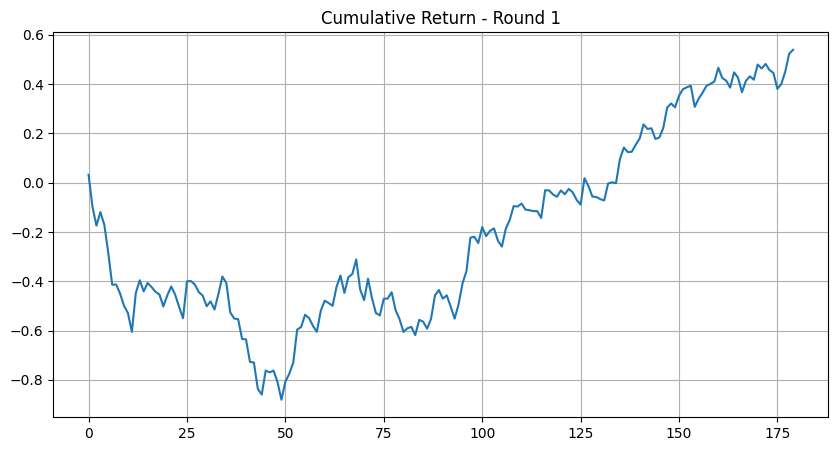

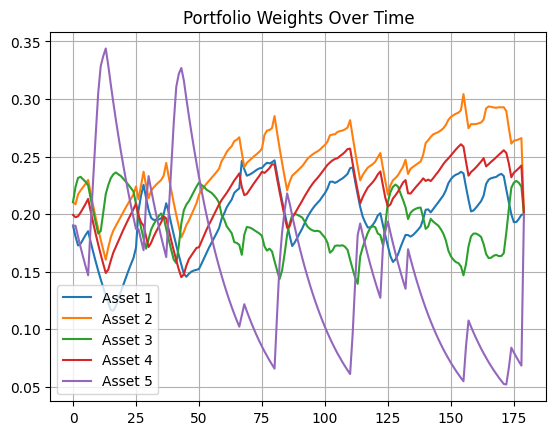

Training round 2
Validation Sharpe Ratio: -0.0834


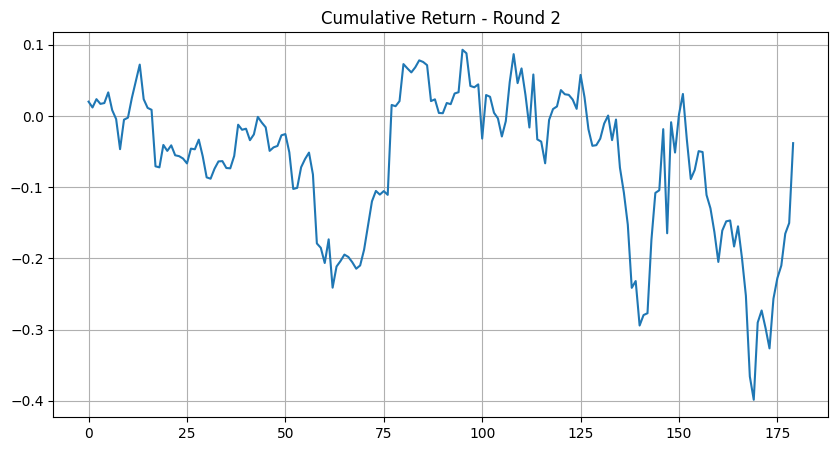

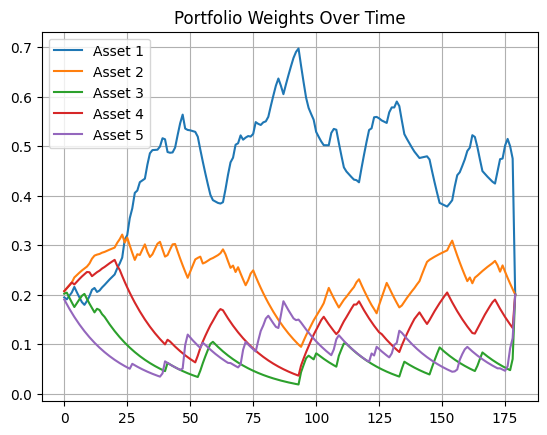

Training round 3
Validation Sharpe Ratio: 1.5634


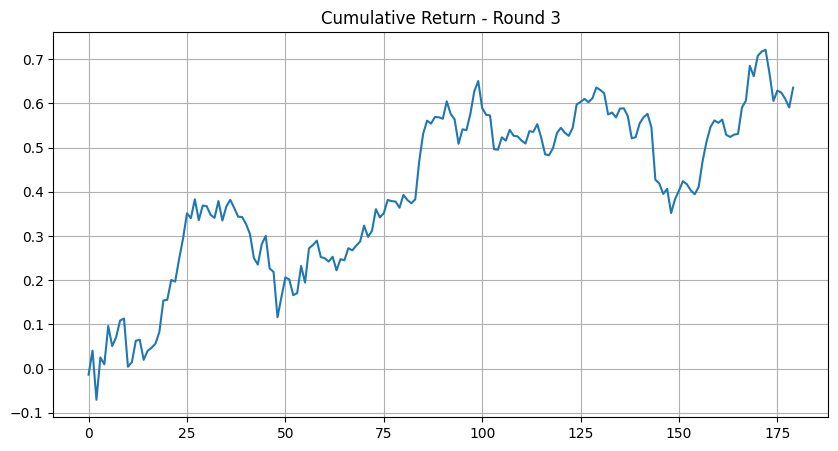

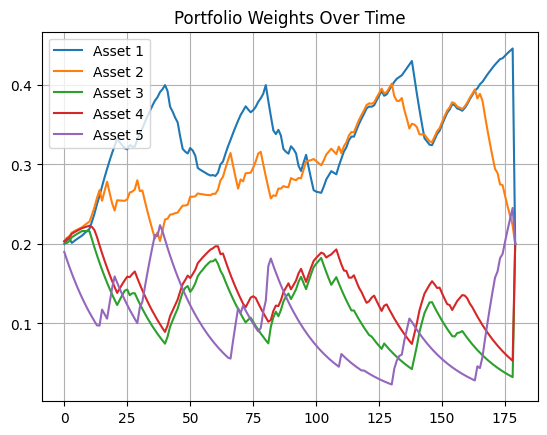

Training round 4
Validation Sharpe Ratio: 2.9484


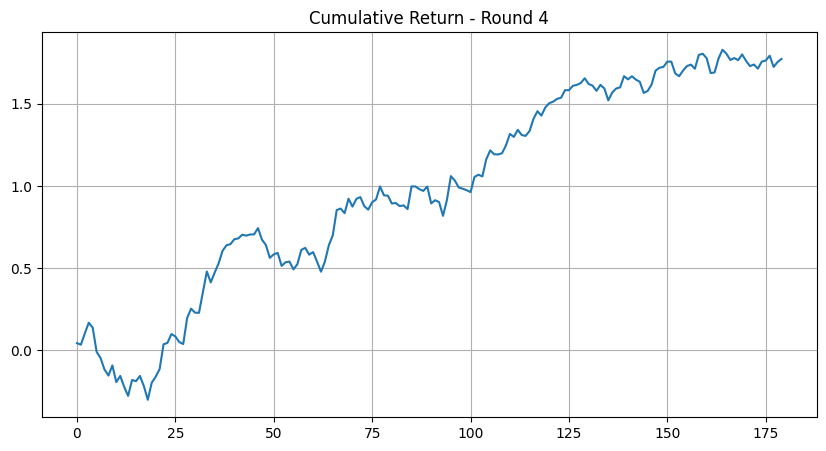

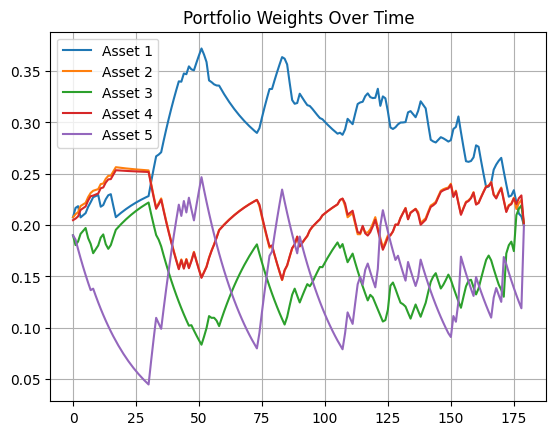

Training round 5
Validation Sharpe Ratio: 0.4549


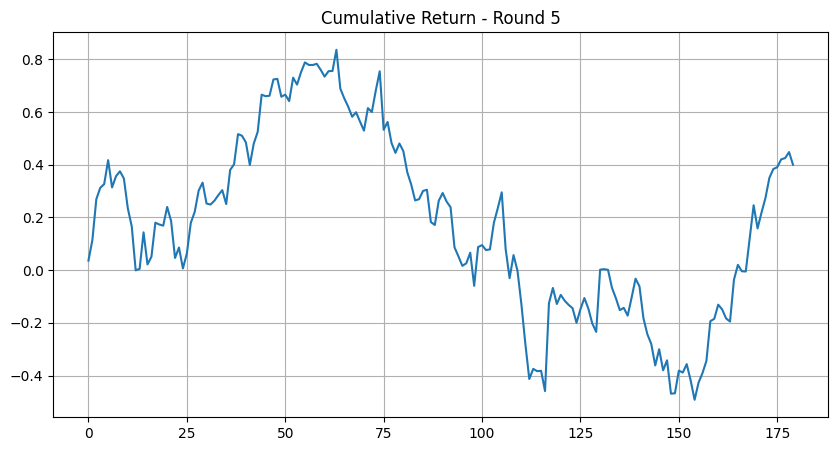

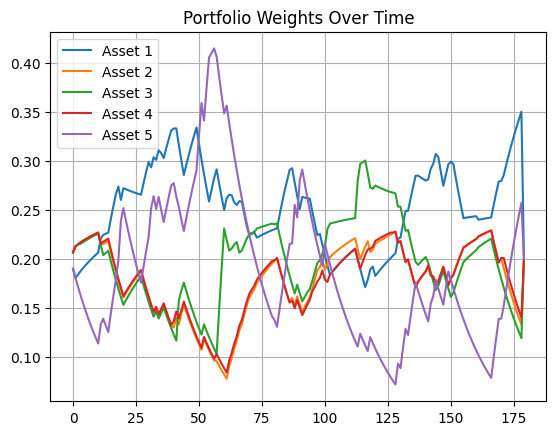

Training round 6
Validation Sharpe Ratio: 1.0913


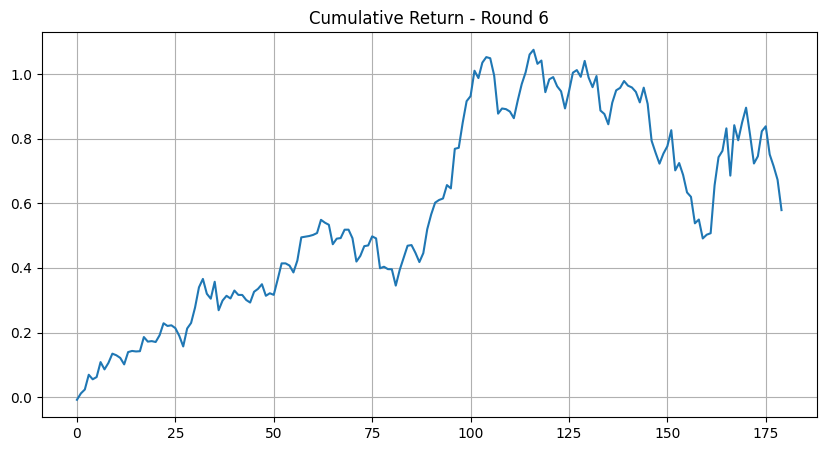

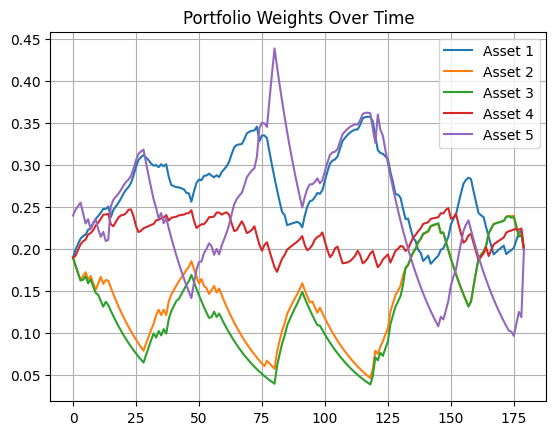

Training round 7
Validation Sharpe Ratio: 1.1004


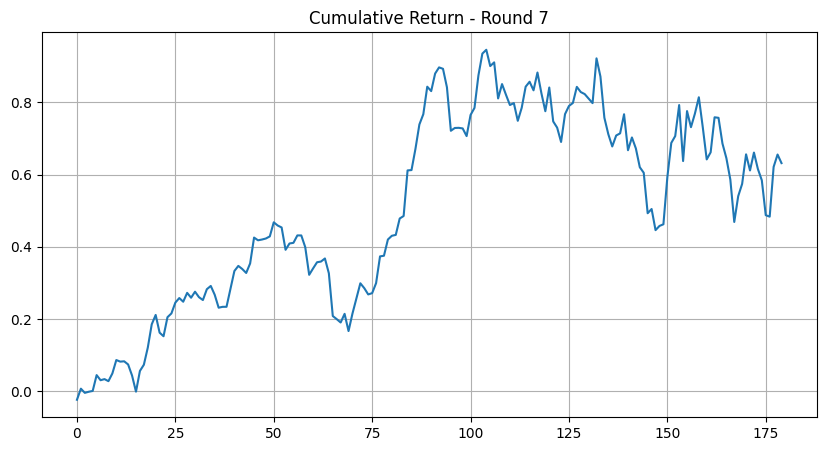

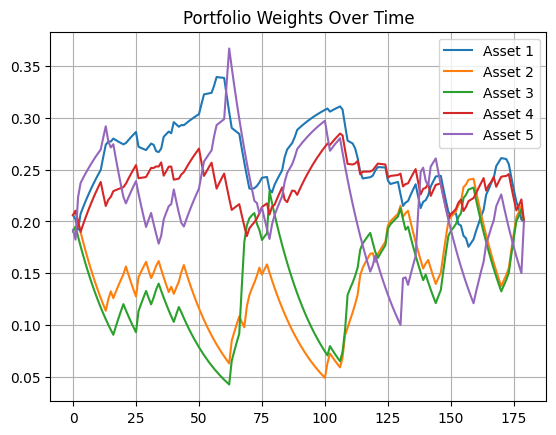

Training round 8
Validation Sharpe Ratio: 0.4012


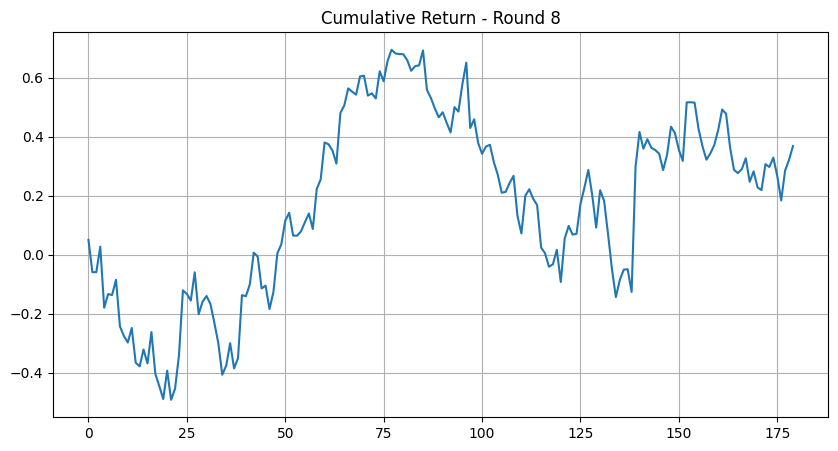

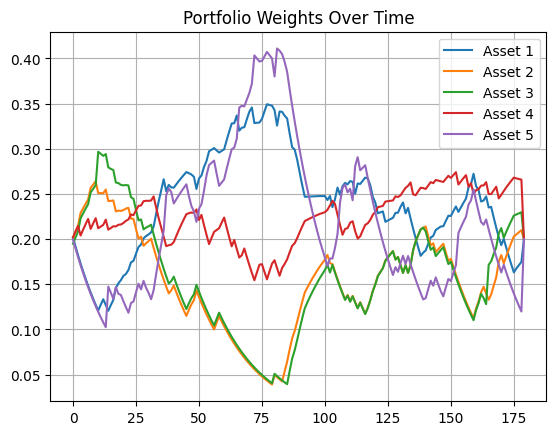

Early stopping triggered.


In [ ]:
# === STEP 1: DOWNLOAD AND NORMALIZE RETURNS ===
tickers = ['AAPL', 'MSFT', 'TSLA', 'AMZN', 'GOOG']
data = yf.download(tickers, start='2015-01-01', end='2025-06-30', auto_adjust=True)['Close'].dropna()
returns = np.log(data / data.shift(1)).dropna()
returns.columns = [f"Asset_{i+1}" for i in range(len(returns.columns))]
unnormalized_returns = returns.copy()

scaler = StandardScaler()
scaled_returns = pd.DataFrame(scaler.fit_transform(returns), index=returns.index, columns=returns.columns)

# === STEP 2: SPLIT INTO DATASETS ===
train_returns = scaled_returns.loc["2015-01-01":"2020-12-31"].copy()
val_returns = scaled_returns.loc["2021-01-01":"2023-12-31"].copy()
test_returns = scaled_returns.loc["2024-01-01":"2025-06-30"].copy()

window_size = 20
episode_length = 180

# === STEP 3: ENVIRONMENT DEFINITION ===
class PortfolioEnv(gym.Env):
    def __init__(self, data, window_size=20, episode_length=180, sharpe_window=50,
                 transaction_cost_rate=0.001, reward_blend=(0.90, 0.10)):
        super().__init__()
        self.data = data.values
        self.window_size = window_size
        self.episode_length = episode_length
        self.sharpe_window = sharpe_window
        self.transaction_cost_rate = transaction_cost_rate
        self.n_assets = self.data.shape[1]

        self.initial_blend = reward_blend
        self.final_blend = (0.80, 0.20)

        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf,
            shape=(self.n_assets * self.window_size,),
            dtype=np.float32
        )
        self.action_space = spaces.Box(low=0, high=1, shape=(self.n_assets,), dtype=np.float32)
        self.returns_buffer = deque(maxlen=self.sharpe_window)
        self.seed()
        self.reset()

    def seed(self, seed=42):
        self.np_random = np.random.RandomState(seed)
        self._seed_value = seed

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self.seed(seed)
        elif not hasattr(self, "_seed_value"):
            self.seed(42)

        max_start = len(self.data) - self.episode_length - 1
        if max_start <= self.window_size:
            raise ValueError("Episode length too long for data size.")

        self.start_step = self.np_random.randint(self.window_size, max_start)
        self.current_step = self.start_step
        self.weights = np.ones(self.n_assets) / self.n_assets
        self.returns_buffer.clear()
        return self._get_observation(), {}

    def _get_observation(self):
        window = self.data[self.current_step - self.window_size + 1: self.current_step + 1]
        obs = window.flatten().astype(np.float32)
        return obs

    def step(self, action):
        action = action / (np.sum(action) + 1e-8)
        r_t = self.data[self.current_step + 1]
        portfolio_return = np.dot(action, r_t)
        portfolio_return = np.clip(portfolio_return, -0.999, None)

        turnover = np.sum(np.abs(action - self.weights))
        transaction_cost = self.transaction_cost_rate * turnover
        allocation_change_penalty = np.sum((action - self.weights) ** 2)
        penalty_weight = 0.1

        self.returns_buffer.append(portfolio_return)
        if len(self.returns_buffer) >= self.sharpe_window:
            mean_r = np.mean(self.returns_buffer)
            std_r = np.std(self.returns_buffer) + 1e-8
            sharpe_reward = mean_r / std_r
        else:
            sharpe_reward = 0.0

        progress = (self.current_step - self.start_step) / self.episode_length
        dynamic_blend_0 = self.initial_blend[0] + progress * (self.final_blend[0] - self.initial_blend[0])
        dynamic_blend_1 = self.initial_blend[1] + progress * (self.final_blend[1] - self.initial_blend[1])

        reward = dynamic_blend_0 * sharpe_reward + dynamic_blend_1 * portfolio_return
        reward -= transaction_cost
        reward -= penalty_weight * allocation_change_penalty

        self.current_step += 1
        done = (self.current_step - self.start_step) >= self.episode_length
        self.weights = 0.95 * self.weights + 0.05 * action

        return self._get_observation(), reward, done, False, {"actual_return": portfolio_return}

# === STEP 4: VALIDATION SETUP
def sharpe_ratio(returns):
        excess = np.array(returns)
        return np.mean(excess) / (np.std(excess) + 1e-8) * np.sqrt(252)

def evaluate_model_on_validation(model, val_env, unnormalized_val_returns, seed=42):
        obs = val_env.reset()
        lstm_states = None
        episode_starts = np.ones((val_env.num_envs,), dtype=bool)
        done = False
        val_returns = []
        weights_over_time = []
        step = val_env.envs[0].current_step

        while not done:
            action, lstm_states = model.predict(obs, state=lstm_states, episode_start=episode_starts, deterministic=True)
            obs, reward, done, info = val_env.step(action)
            episode_starts = np.array([done])
            actual_ret = unnormalized_val_returns.iloc[step + 1].values
            portfolio_ret = np.dot(action[0], actual_ret)
            simple_ret = np.exp(portfolio_ret) - 1
            val_returns.append(simple_ret)

            weights_over_time.append(val_env.envs[0].weights.copy())
            step += 1

        return sharpe_ratio(val_returns), val_returns, weights_over_time

# === STEP 5: TRAIN MODEL ===
log_dir = str(REPO_ROOT / "ppo_tensorboard")
os.makedirs(log_dir, exist_ok=True)
writer = SummaryWriter(log_dir=log_dir)

train_env = DummyVecEnv([lambda: PortfolioEnv(train_returns)])
val_env = DummyVecEnv([lambda: PortfolioEnv(val_returns)])

seeds = [0, 42, 77, 123, 999]  # List of different seeds
best_seed = None
best_sharpe = -np.inf

for seed in seeds:
    print(f"\n🚀 Training with seed {seed}")

    # Set seed for reproducibility
    train_env = DummyVecEnv([lambda: PortfolioEnv(train_returns)])
    val_env = DummyVecEnv([lambda: PortfolioEnv(val_returns)])

    # Set the global seed for reproducibility (optional)
    set_random_seed(seed)

    model = RecurrentPPO(
        "MlpLstmPolicy",
        train_env,
        verbose=0,
        n_steps=128,
        learning_rate=0.0001,
        ent_coef=0.01,
        batch_size=64,
        tensorboard_log=None,
        seed=seed
    )

best_model = None
best_sharpe = -np.inf
patience = 4
no_improve_counter = 0
train_steps_per_round = 50000
max_rounds = 10

for round in range(max_rounds):
    print(f"Training round {round + 1}")
    model.learn(total_timesteps=train_steps_per_round, reset_num_timesteps=False, tb_log_name="ppo_run")

    val_sharpe, val_returns_list, val_weights = evaluate_model_on_validation(
        model, val_env, unnormalized_returns.loc["2021-01-01":"2023-12-31"]
    )

    print(f"Validation Sharpe Ratio: {val_sharpe:.4f}")

    writer.add_scalar("val/Sharpe_Ratio", val_sharpe, round)
    writer.add_scalar("val/Cumulative_Return", np.sum(val_returns_list), round)

    val_weights = np.array(val_weights)
    mean_weights = np.mean(val_weights, axis=0)
    for i, w in enumerate(mean_weights):
        writer.add_scalar(f"val/Avg_Weight_Asset_{i+1}", w, round)

    plt.figure(figsize=(10, 5))
    plt.plot(np.cumsum(val_returns_list))
    plt.title(f"Cumulative Return - Round {round + 1}")
    plt.grid(True)
    plt.show()

    for i in range(val_weights.shape[1]):
        plt.plot(val_weights[:, i], label=f'Asset {i+1}')
    plt.title("Portfolio Weights Over Time")
    plt.legend()
    plt.grid(True)
    plt.show()

    if val_sharpe > best_sharpe + 1e-4:
        best_sharpe = val_sharpe
        model_path = str(REPO_ROOT / "models" / "runs" / "intermediate" / f"ppo_best_model_round{round+1}.zip")
        Path(model_path).parent.mkdir(parents=True, exist_ok=True)
        model.save(model_path)
        best_model = RecurrentPPO.load(model_path, env=train_env)  # Correctly load the same path
        no_improve_counter = 0
    else:
        no_improve_counter += 1

    if no_improve_counter >= patience:
        print("Early stopping triggered.")
        break


writer.close()


In [ ]:
%load_ext tensorboard
%tensorboard --logdir ./ppo_tensorboard/